<a href="https://colab.research.google.com/github/na0664280-dev/thakaa-flow-training/blob/main/week2/day08/day08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Task 1

In [19]:
### 1. Garbage in, Garbage Out

- الداتا: مبيعات كافيه يومية بالريال
- الخطأ الصغير: يوم من الأيام انكتبت مبيعاته 24100 بدل 2410 (صفر زيادة)
- القرار الخاطئ: الموديل يحسب إن متوسط المبيعات أعلى بكثير من الواقع، فيتوقع مبيعات ضخمة للأسبوع القادم، والكافيه يطلب مخزون زيادة ويخسر

## 2. اكتشاف المشاكل

| المشكلة | مكانها | نوعها | قراري للعلاج | سبب القرار |
|---|---|---|---|---|
| قيمة فاضية | age، الطلب 1003 | Null | أعوضها بالوسيط | الوسيط ما يتأثر بالقيم الشاذة |
| عمر 250 | age، الطلب 1004 | Outlier | أحذف الصف أو أعوضها بالوسيط | العمر مستحيل، خطأ إدخال |
| صف مكرر | الطلب 1002 | Duplicate | أحذف النسخة الثانية | نفس الطلب انحسب مرتين |
| riyadh و Riyadh | city، الطلب 1002 | Inconsistency | أوحدها كلها Riyadh | الموديل يعدهم مدينتين مختلفتين |
| three hundred | amount، الطلب 1005 | Wrong type | أحوّلها إلى 300 | الموديل يحتاج رقم مو نص |

## 3. Target و Features

**المشكلة:** توقع زحمة طريق الملك فهد في الرياض

**Target:** مدة الرحلة بالدقائق

**Features:**
1. وقت اليوم (الساعة)
2. يوم الأسبوع
3. حالة الطقس
4. وجود مناسبة أو إجازة
5. وجود حادث على الطريق

**عمود لن أدخله:** رقم لوحة السيارة

**السبب:** ما له علاقة بمدة الرحلة، ويضيف ضجيج للموديل، وفيه خصوصية.

## 4. ليش تجهيز الداتا أهم؟

لأن الموديل يتعلم من الداتا اللي نعطيه، فلو فيها أخطاء أو قيم ناقصة بيتعلم أشياء غلط ويعطي قرارات غلط (Garbage In, Garbage Out). بناء الموديل ممكن يتم بسطر كود، لكن تنظيف الداتا يحتاج فهم وتدقيق. فالموديل الممتاز على داتا سيئة أسوأ من موديل بسيط على داتا نظيفة.

## task2

In [20]:
import numpy as np
import pandas as pd

print(np.__version__)
print(pd.__version__)

2.4.6
2.2.3


In [21]:
!unzip archive.zip

Archive:  archive.zip
replace insurance.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [22]:
df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [23]:
!unzip -o "archive (1).zip"

Archive:  archive (1).zip
  inflating: test_Y3wMUE5_7gLdaTN.csv  
  inflating: train_u6lujuX_CVtuZ9i.csv  


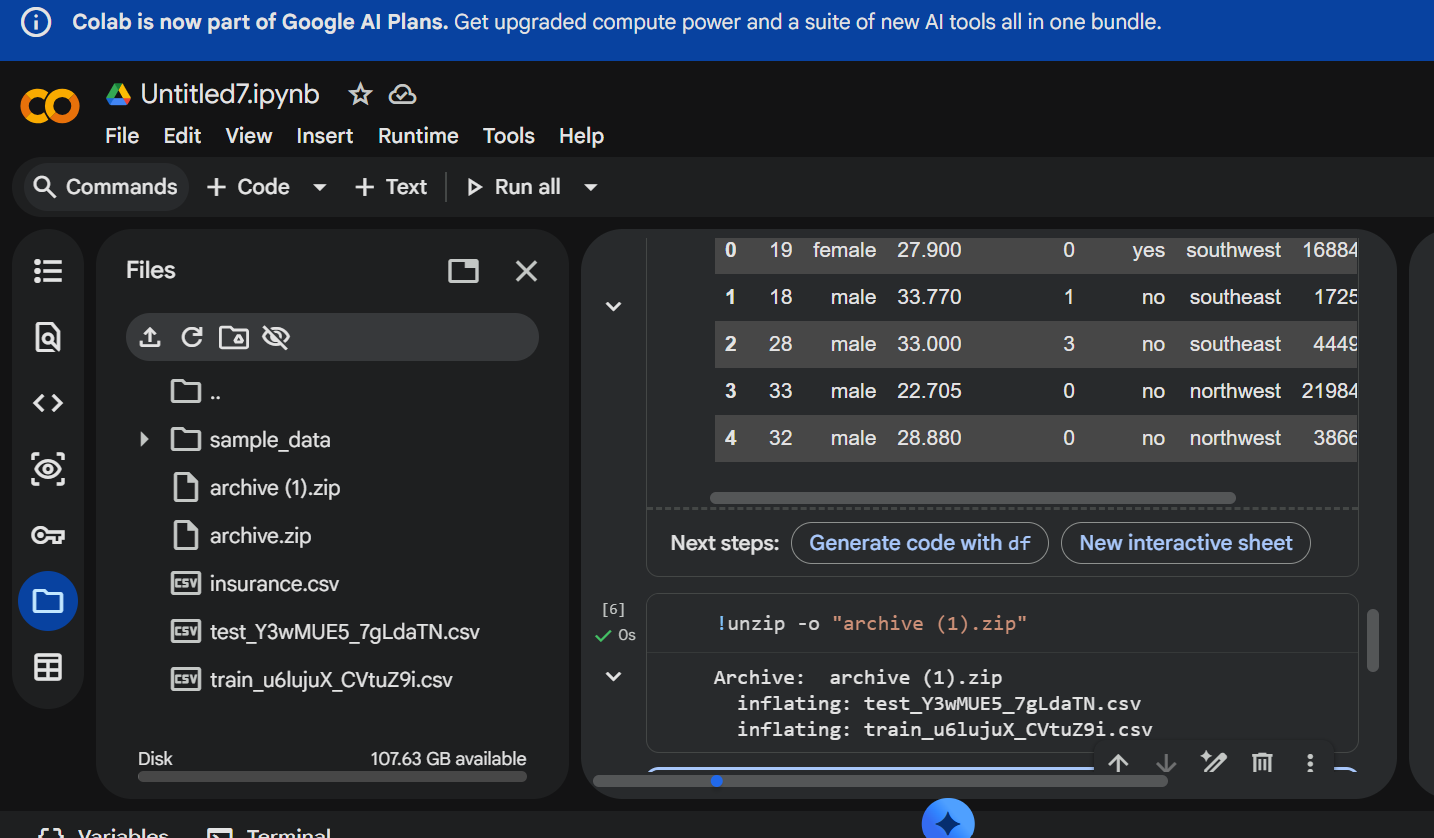

### توقعي قبل التشغيل
- print(prices_list * 2) ← [25, 18, 32, 25, 18, 32] (القائمة تتكرر)
- print(prices * 2) ← [50 36 64] (كل رقم يتضاعف)
- print(prices_list + [1, 1, 1]) ← [25, 18, 32, 1, 1, 1] (القائمتين تلتصق)
- print(prices + np.array([1, 1, 1])) ← [26 19 33] (جمع رقم برقم)

In [24]:
prices_list = [25, 18, 32]
prices = np.array(prices_list)

print(prices_list * 2)
print(prices * 2)
print(prices_list + [1, 1, 1])
print(prices + np.array([1, 1, 1]))

[25, 18, 32, 25, 18, 32]
[50 36 64]
[25, 18, 32, 1, 1, 1]
[26 19 33]


In [25]:
print(prices.shape)
print(prices.ndim)
print(prices.size)
print(prices.dtype)

(3,)
1
3
int64


In [26]:
a = np.array([1, 2.5, 3])
b = np.array([1, "2", 3])

print(a, a.dtype)
print(b, b.dtype)

[1.  2.5 3. ] float64
['1' '2' '3'] <U21


### شرح النتيجة
- في a: القيم كانت أرقام صحيحة وعشرية، فحوّل NumPy الـ 1 و 3 إلى 1.0 و 3.0 عشان الكل يصير float64.
- في b: دخل نص "2" وسط الأرقام، فحوّل NumPy كل العناصر لنص (<U21).
- ليش الـ array يحتاج نوع واحد؟ لأن NumPy يخزّن البيانات متجاورة في الذاكرة بنوع ثابت، وهذا اللي يخليه سريع ويقدر يسوي العمليات الحسابية على كل العناصر دفعة وحدة. ولو اختلطت الأنواع ما تنفع العمليات (مثلاً ما تقدر تضرب نص في رقم).

## Task3

In [27]:
days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
sales = np.array([1240, 980, 1105, 1320, 1875, 2410, 2150])

# السؤال 1
print("Total:", sales.sum())
print("Mean:", round(sales.mean(), 2))
print("Median:", np.median(sales))
print("Max:", sales.max(), "| Min:", sales.min())
print("Std:", round(sales.std(), 1))

# السؤال 2
print("Best day:", days[sales.argmax()], sales.max())
print("Worst day:", days[sales.argmin()], sales.min())

Total: 11080
Mean: 1582.86
Median: 1320.0
Max: 2410 | Min: 980
Std: 516.8
Best day: Fri 2410
Worst day: Mon 980


In [28]:
# السؤال 3
mask = sales > sales.mean()
print("Above average:", mask)
print("Days above average:", mask.sum())
print("Their sales:", sales[mask])

# السؤال 4
weekend = sales[5:7]
print("Weekend total:", weekend.sum(), "| share:", round(weekend.sum() / sales.sum() * 100, 1), "%")

Above average: [False False False False  True  True  True]
Days above average: 3
Their sales: [1875 2410 2150]
Weekend total: 4560 | share: 41.2 %


In [29]:
# السؤال 5
after_tax = sales * 0.85
target = sales * 1.10
print("After tax:", after_tax)
print("Next week target:", target)

# السؤال 6
changes = np.diff(sales)
print("Changes:", changes)
biggest = changes.argmax()
print("Biggest jump:", days[biggest], "->", days[biggest + 1], changes[biggest])

After tax: [1054.    833.    939.25 1122.   1593.75 2048.5  1827.5 ]
Next week target: [1364.  1078.  1215.5 1452.  2062.5 2651.  2365. ]
Changes: [-260  125  215  555  535 -260]
Biggest jump: Wed -> Thu 555


## قرار: كم أبيع في يوم عادي؟

المتوسط (1582.86) أكبر من الوسيط (1320). السبب إن أيام الخميس والجمعة والسبت مبيعاتها عالية (1875 و 2410 و 2150) وترفع المتوسط، بينما أغلب الأيام العادية أقل من كذا.

لو سألني صاحب الكافيه "كم أبيع في يوم عادي؟" بعطيه **الوسيط (1320)**، لأنه يمثل اليوم العادي فعلًا ولا يتأثر بأيام الويكند العالية. أما المتوسط فيعطي صورة أعلى من الواقع لباقي الأسبوع.

## Task4

In [30]:
branches = ["Riyadh", "Jeddah", "Dammam"]
days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
sales = np.array([
    [1240, 980, 1105, 1320, 1875, 2410, 2150],
    [910, 870, 990, 1010, 1430, 1980, 2240],
    [640, 720, 680, 750, 990, 1210, 1080],
])

# السؤال 1
print("Shape:", sales.shape)

# السؤال 2
print("Jeddah Thursday:", sales[1, 4])
print("Dammam whole week:", sales[2])
print("All branches Friday:", sales[:, 5])
print("All branches Fri & Sat:", sales[:, 5:7])

# السؤال 3
print("Branch totals (axis=1):", sales.sum(axis=1))
print("Day totals (axis=0):", sales.sum(axis=0))

Shape: (3, 7)
Jeddah Thursday: 1430
Dammam whole week: [ 640  720  680  750  990 1210 1080]
All branches Friday: [2410 1980 1210]
All branches Fri & Sat: [[2410 2150]
 [1980 2240]
 [1210 1080]]
Branch totals (axis=1): [11080  9430  6070]
Day totals (axis=0): [2790 2570 2775 3080 4295 5600 5470]


In [31]:
branches = ["Riyadh", "Jeddah", "Dammam"]
days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
sales = np.array([
    [1240, 980, 1105, 1320, 1875, 2410, 2150],
    [910, 870, 990, 1010, 1430, 1980, 2240],
    [640, 720, 680, 750, 990, 1210, 1080],
])

print("Shape:", sales.shape)

print("Jeddah Thursday:", sales[1, 4])
print("Dammam whole week:", sales[2])
print("All branches Friday:", sales[:, 5])
print("All branches Fri & Sat:", sales[:, 5:7])

print("Branch totals (axis=1):", sales.sum(axis=1))
print("Day totals (axis=0):", sales.sum(axis=0))

Shape: (3, 7)
Jeddah Thursday: 1430
Dammam whole week: [ 640  720  680  750  990 1210 1080]
All branches Friday: [2410 1980 1210]
All branches Fri & Sat: [[2410 2150]
 [1980 2240]
 [1210 1080]]
Branch totals (axis=1): [11080  9430  6070]
Day totals (axis=0): [2790 2570 2775 3080 4295 5600 5470]


### شرح
- shape = (3, 7): الرقم الأول 3 هو عدد الفروع (الصفوف)، والرقم الثاني 7 هو عدد الأيام (الأعمدة).
- axis=1: يجمع على طول الصف، يعني مجموع كل فرع على أيام الأسبوع.
- axis=0: يجمع على طول العمود، يعني مجموع كل يوم على كل الفروع.

In [32]:
branches = ["Riyadh", "Jeddah", "Dammam"]
days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
sales = np.array([
    [1240, 980, 1105, 1320, 1875, 2410, 2150],
    [910, 870, 990, 1010, 1430, 1980, 2240],
    [640, 720, 680, 750, 990, 1210, 1080],
])

print("Shape:", sales.shape)

print("Jeddah Thursday:", sales[1, 4])
print("Dammam whole week:", sales[2])
print("All branches Friday:", sales[:, 5])
print("All branches Fri & Sat:", sales[:, 5:7])

print("Branch totals (axis=1):", sales.sum(axis=1))
print("Day totals (axis=0):", sales.sum(axis=0))

Shape: (3, 7)
Jeddah Thursday: 1430
Dammam whole week: [ 640  720  680  750  990 1210 1080]
All branches Friday: [2410 1980 1210]
All branches Fri & Sat: [[2410 2150]
 [1980 2240]
 [1210 1080]]
Branch totals (axis=1): [11080  9430  6070]
Day totals (axis=0): [2790 2570 2775 3080 4295 5600 5470]


In [33]:
# السؤال 4
branch_totals = sales.sum(axis=1)
day_totals = sales.sum(axis=0)
total = sales.sum()

print("Best branch:", branches[branch_totals.argmax()])
print("Best day overall:", days[day_totals.argmax()])
for i in range(3):
    print(branches[i], "share:", round(branch_totals[i] / total * 100, 1), "%")

# السؤال 5
flat_index = sales.argmax()
row = flat_index // 7
col = flat_index % 7
print("Highest single cell:", branches[row], days[col], sales[row, col])

Best branch: Riyadh
Best day overall: Fri
Riyadh share: 41.7 %
Jeddah share: 35.5 %
Dammam share: 22.8 %
Highest single cell: Riyadh Fri 2410


## قرار: إغلاق فرع واحد يوم الأحد

أقترح إغلاق **فرع الدمام** يوم الأحد.

الأرقام:
- مبيعات الدمام يوم الأحد: 640 ريال، وهي أقل رقم بين الفروع في ذلك اليوم (الرياض 1240، جدة 910).
- الدمام أقل فرع في المجموع: 6070 ريال، بنسبة 22.8% فقط من مبيعات الشركة.
- خسارة الإغلاق قليلة: 640 ريال فقط من إجمالي 26580 ريال في الأسبوع (حوالي 2.4%).

بينما إغلاق الرياض يخسّر الشركة 1240 ريال في يوم واحد، وهذا أكبر بكثير.

##Task5

In [34]:
depth = np.array([120, 340, 610, -1, 890, 1150, 1420, 99999, 1730, 2010,
                  2280, -1, 2560, 2840, 99999, 3120, 3390, 3650, -1, 3900])

# السؤال 1
bad_mask = (depth == -1) | (depth == 99999)
print("Bad readings:", bad_mask.sum())
print("Bad share:", round(bad_mask.sum() / depth.size * 100, 1), "%")

# السؤال 2
mean_with_bad = depth.mean()
mean_clean = depth[~bad_mask].mean()
print("Mean with bad:", round(mean_with_bad, 2))
print("Mean clean:", round(mean_clean, 2))
print("Error multiplier:", round(mean_with_bad / mean_clean, 2))

# السؤال 3
clean = depth[~bad_mask]
print("Median:", np.median(clean))
print("Max (m):", clean.max(), "| Max (ft):", round(clean.max() * 3.28084, 1))

Bad readings: 5
Bad share: 25.0 %
Mean with bad: 11500.25
Mean clean: 2000.67
Error multiplier: 5.75
Median: 2010.0
Max (m): 3900 | Max (ft): 12795.3


In [35]:
# السؤال 4
pressure = clean / 10 + 1
print("Pressure:", pressure)
print("Readings over 300 atm:", (pressure > 300).sum())

# السؤال 5
speed = np.diff(clean)
print("Descent speed (m/min):", speed)
print("Min speed:", speed.min(), "| Max speed:", speed.max())

Pressure: [ 13.  35.  62.  90. 116. 143. 174. 202. 229. 257. 285. 313. 340. 366.
 391.]
Readings over 300 atm: 4
Descent speed (m/min): [220 270 280 260 270 310 280 270 280 280 280 270 260 250]
Min speed: 220 | Max speed: 310


## تحليل سرعة النزول

سرعة النزول بين 220 و 310 متر بالدقيقة، فهي ثابتة تقريبًا، ما فيه تسارع أو توقف مفاجئ.

## قرار: نحذف القراءات الخاطئة ولا نملؤها؟

لو أردنا تدريب موديل يتوقع عمق الغواصة بعد 10 دقائق، أحذف القراءات الخاطئة (5 قراءات، 25% من الداتا) بدل ما أملؤها.

السبب: القيمة -1 تعني فقدان إشارة و 99999 خطأ في الحساس، فهي ليست قياسات حقيقية. لو تركتها، 99999 ترفع المتوسط بشكل كبير وتخرّب تعلم الموديل (Garbage In, Garbage Out).

وبما إن النزول ثابت تقريبًا، فلو احتجت أملأ القراءة المفقودة، أملؤها بمتوسط القراءة اللي قبلها واللي بعدها، لأن العمق يتغير بشكل منتظم. لكن الحذف أبسط وأأمن لأن عندي 15 قراءة سليمة تكفي.